# ADRIA × ENSET — Partie H : Détection de fraude bancaire
**Spécialisation ciblée : Data Science / Big Data**  
Jeu analysé : `bank_transactions.csv` fourni dans l'épreuve.  
Méthodologie : **EDA → qualité des données → préparation sans fuite → comparaison CV → évaluation sur test gelé → interprétation métier.**

> Ce notebook est exécuté sur le fichier fourni, et les résultats visibles proviennent effectivement du pipeline Python. Aucun déploiement en microservice n'est demandé pour le modèle.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
from train import evaluate, FEATURES, NUMERIC, CATEGORICAL
DATA = Path('data/bank_transactions.csv')
RESULTS = Path('results')
df = pd.read_csv(DATA)
print('Dimension du jeu de données :', df.shape)
display(df.head(5))

Dimension du jeu de données : (5000, 9)


,transaction_id,account_id,amount,hour,country,merchant_category,transactions_last_24h,average_amount_last_7d,is_fraud
0,TX000001,ACC0090,383.72,4,FR,ECOMMERCE,6,217.44,0
1,TX000002,ACC0774,516.48,0,BE,ECOMMERCE,1,275.06,0
2,TX000003,ACC0655,151.95,15,DE,GROCERY,1,100.82,0
3,TX000004,ACC0439,34.56,16,FR,GROCERY,4,33.88,0
4,TX000005,ACC0434,93.14,18,FR,TRANSPORT,0,276.66,0


## 1. Exploration et qualité des données
La cible `is_fraud` est très déséquilibrée. Les deux identifiants ne sont **jamais** utilisés comme variables explicatives. Certaines colonnes présentent des valeurs manquantes ; l'imputation sera intégrée à un `Pipeline` pour éviter toute fuite de données entre apprentissage et test.

In [2]:
display(pd.DataFrame({'effectif':df.is_fraud.value_counts().sort_index(),
                            'part':df.is_fraud.value_counts(normalize=True).sort_index()}))
missing=df.isna().sum().to_frame('valeurs_manquantes')
missing['pourcentage']=missing['valeurs_manquantes']/len(df)*100
display(missing)
print('Duplicats de transaction_id :',df.transaction_id.duplicated().sum())
print('Comptes différents :',df.account_id.nunique())

,effectif,part
is_fraud,,
0,4743,0.9486
1,257,0.0514


,valeurs_manquantes,pourcentage
transaction_id,0,0.00
account_id,0,0.00
amount,0,0.00
hour,0,0.00
country,66,1.32
merchant_category,84,1.68
transactions_last_24h,0,0.00
average_amount_last_7d,75,1.50
is_fraud,0,0.00


Duplicats de transaction_id : 0
Comptes différents : 988


## 2. Analyse descriptive par classe
Ces statistiques aident à comprendre les distributions et à préparer les questions du jury. Elles ne prouvent pas qu'une variable cause la fraude.

In [3]:
display(df.groupby('is_fraud')[['amount','hour','transactions_last_24h','average_amount_last_7d']].agg(['median','mean']).round(2))
display(df.groupby('merchant_category',dropna=False)['is_fraud'].agg(['count','mean']).sort_values('mean',ascending=False))

amount           hour  ... transactions_last_24h average_amount_last_7d        
          median    mean median  ...                  mean                 median    mean
is_fraud                         ...                                                     
0          68.67  121.49   11.0  ...                  3.72                  81.33  104.31
1         109.11  252.21    8.0  ...                  5.87                  83.78  104.06

[2 rows x 8 columns]

,count,mean
merchant_category,,
ELECTRONICS,479,0.073069
ECOMMERCE,1047,0.063992
RESTAURANT,960,0.057292
TRANSPORT,725,0.046897
GROCERY,1230,0.037398
TRAVEL,475,0.035789
NaN,84,0.035714


## 3. Modèles, validation croisée et évaluation indépendante

- Séparation stratifiée : **75 % apprentissage / 25 % test**, `random_state=42`.
- `ColumnTransformer` : imputation médiane et standardisation numériques ; imputation par mode et One-Hot des catégories.
- Sur l'entraînement uniquement : **3 modèles** comparés par **Average Precision** en CV à 3 plis.
- Sélection du meilleur modèle **sans regarder le test** ; seuil secondaire choisi sur probabilités hors-pli de l'entraînement (F1), et seuil fixe 0,50 conservé comme référence.
- Évaluation finale du test indépendant : précision, rappel, F1, matrice de confusion, Average Precision.
- Le CSV n'a pas de date chronologique : **validation temporelle impossible dans cette épreuve**, mais à privilégier sur des données historiques en production.

In [4]:
metrics = evaluate(df,RESULTS)
print('Modèle sélectionné :', metrics['selected_model'])
print('Average precision / test :',round(metrics['test_average_precision'],4))
print('Seuil appris sur train (OOF) :',metrics['oof_training_selected_threshold'])
display(pd.read_csv(RESULTS/'comparaison_modeles_cv.csv').round(4))

Modèle sélectionné : Régression logistique (pondérée)
Average precision / test : 0.1885
Seuil appris sur train (OOF) : 0.8


,modele,cv_ap_moyenne,cv_ap_ecart_type
0,Régression logistique (pondérée),0.1833,0.0209
1,Arbre de décision (pondéré),0.0935,0.0150
2,Random Forest (pondérée),0.1131,0.0127


## 4. Résultats : interprétation honnête
Une accuracy élevée ne suffit pas : la stratégie « toujours non-fraude » donne une grande accuracy avec un rappel de 0. Le seuil de 0,50 vise une détection plus sensible, au prix de nombreuses fausses alertes. Le seuil optimisé sur l'apprentissage illustre un autre compromis, **sans être sélectionné sur le test**.

In [5]:
f=metrics['test_threshold_fixed_0_50']
t=metrics['test_threshold_selected_on_training']
base=metrics['baseline_always_non_fraud']
rows=[]
for label,m in [('Toujours non-fraude',base),('Modèle, seuil 0.50',f),('Modèle, seuil choisi sur train',t)]:
    rows.append({'Approche':label,'Seuil':m['seuil'],'Accuracy':m['accuracy'],
                 'Précision fraude':m['precision_fraude'],'Rappel fraude':m['rappel_fraude'],
                 'F1 fraude':m['f1_fraude'],'Faux positifs':m['faux_positifs'],
                 'Fraudes manquées':m['faux_negatifs']})
display(pd.DataFrame(rows).round(3))
print('Matrice de confusion :',f['matrice_confusion'])

,Approche,Seuil,Accuracy,Précision fraude,Rappel fraude,F1 fraude,Faux positifs,Fraudes manquées
0,Toujours non-fraude,0.5,0.949,0.000,0.000,0.000,0,64
1,"Modèle, seuil 0.50",0.5,0.734,0.104,0.547,0.174,303,29
2,"Modèle, seuil choisi sur train",0.8,0.925,0.232,0.203,0.217,43,51


Matrice de confusion : [[883, 303], [29, 35]]


## 5. Visualisations produites à partir du CSV fourni

**repartition fraudes.png**

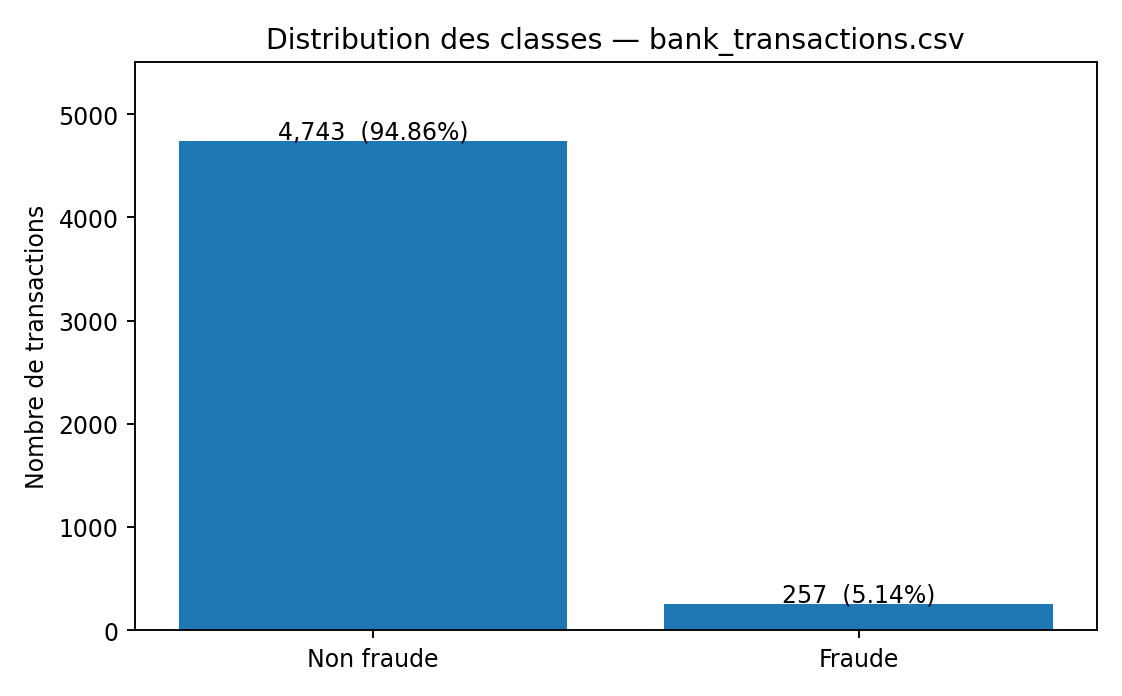

**valeurs manquantes.png**

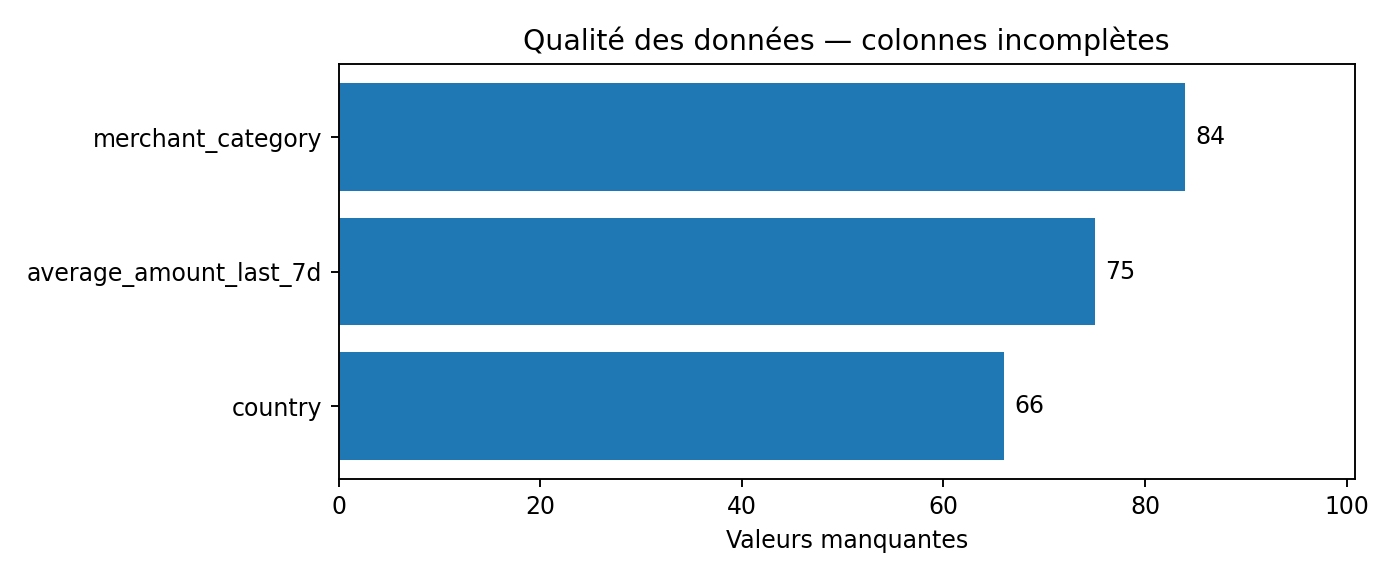

**comparaison modeles.png**

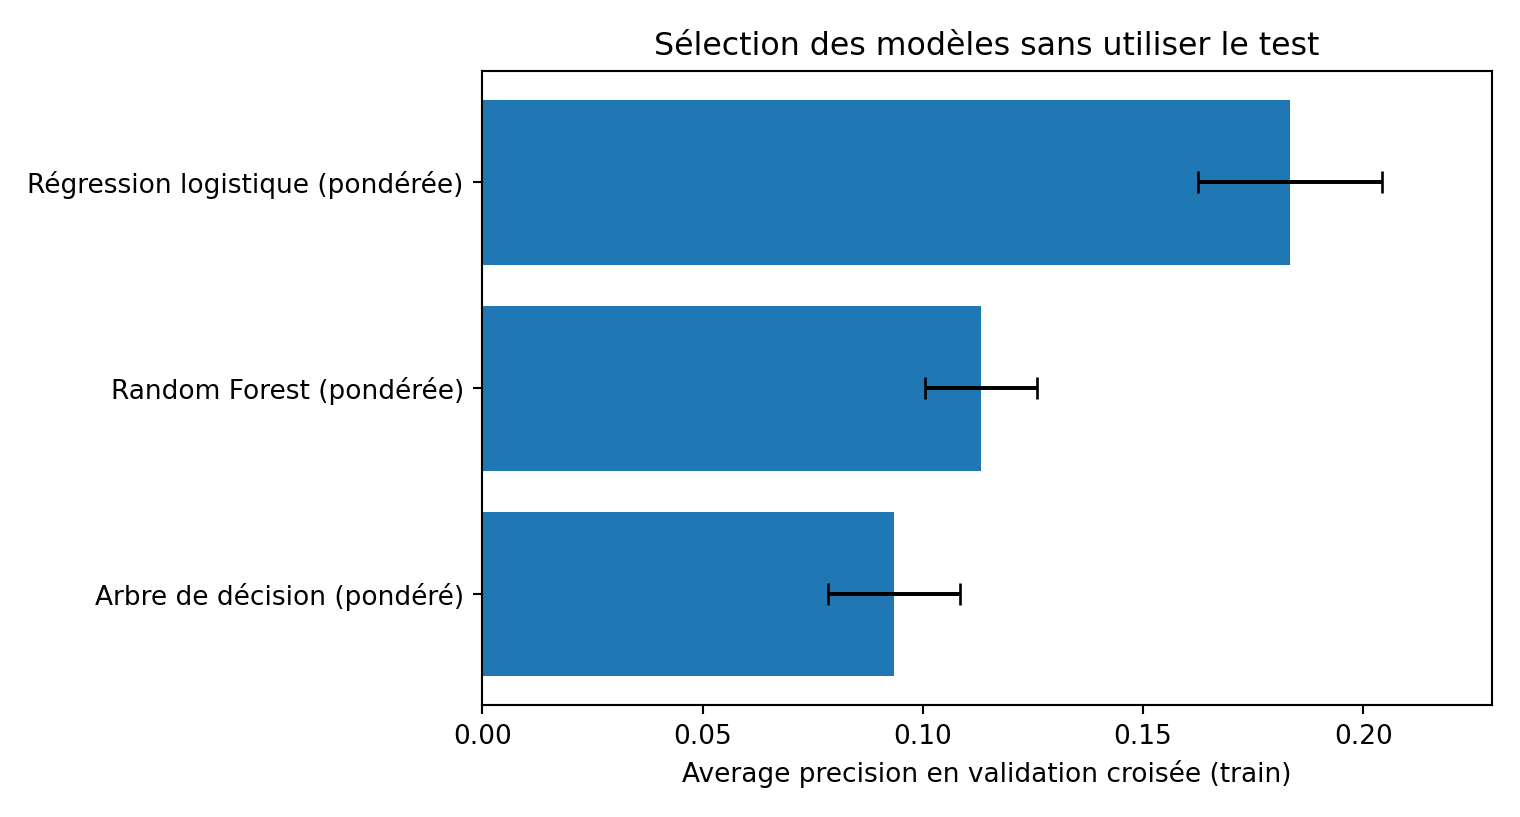

**confusion matrix.png**

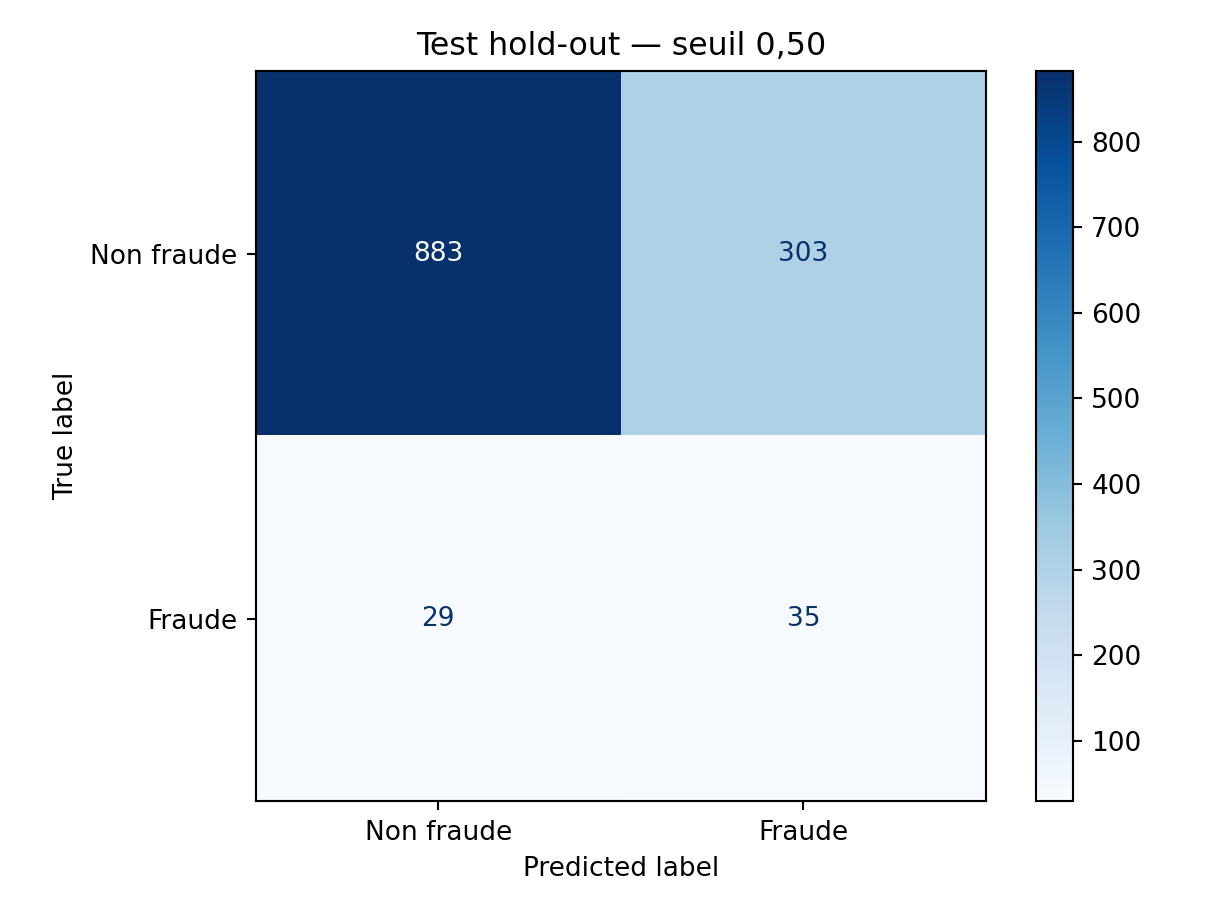

**precision recall.png**

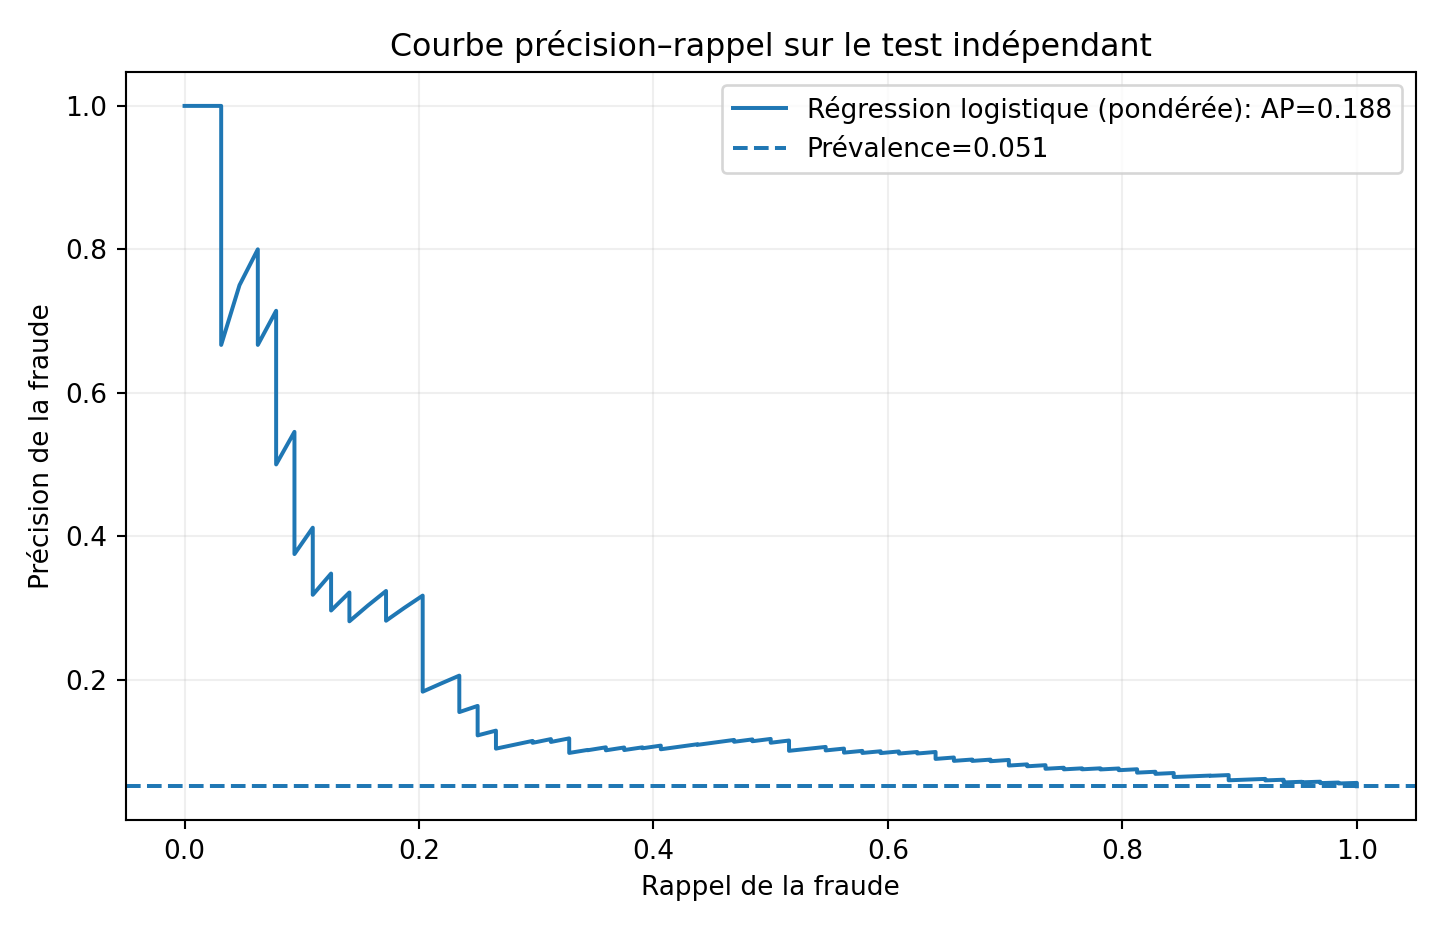

**analyse seuil sur train.png**

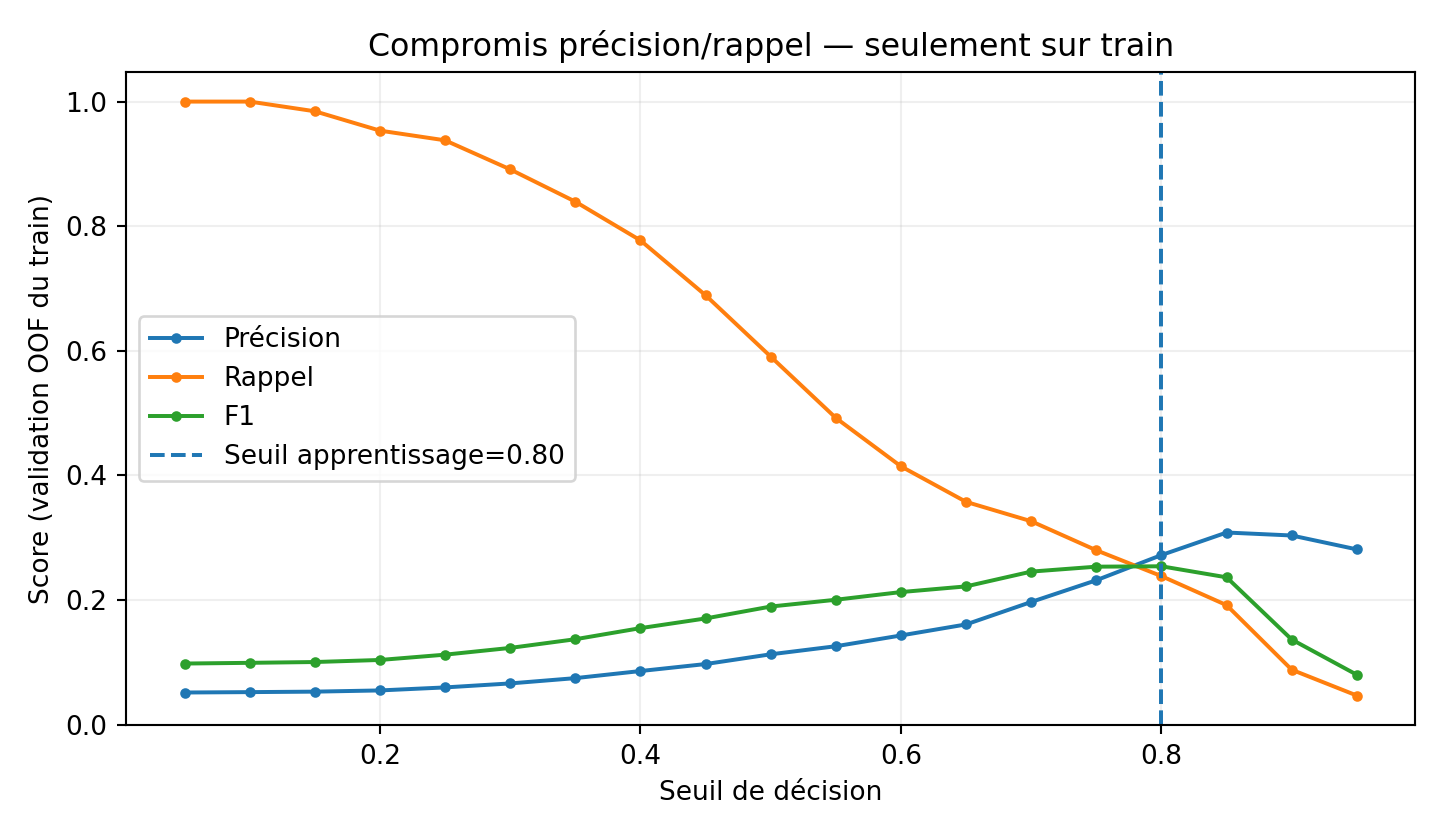

**importance variables.png**

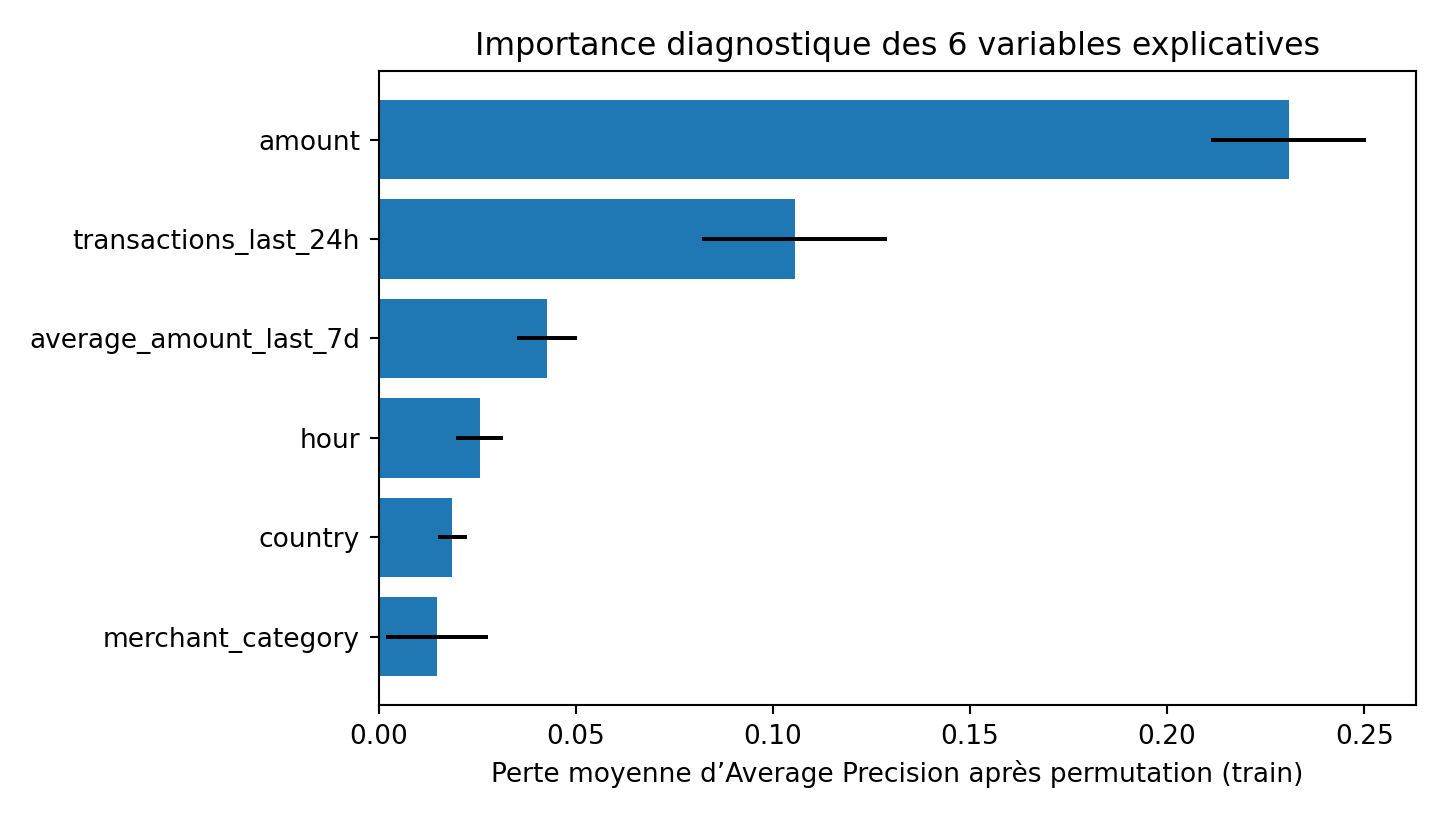

In [6]:
for filename in ['repartition_fraudes.png','valeurs_manquantes.png','comparaison_modeles.png',
                 'confusion_matrix.png','precision_recall.png','analyse_seuil_sur_train.png',
                 'importance_variables.png']:
    display(Markdown('**'+filename.replace('_',' ')+'**'))
    display(Image(filename=str(RESULTS/filename),width=570))

## 6. Interprétation des variables et limites
L'importance par permutation est calculée **sur un sous-échantillon du train**, après sélection du modèle. Elle représente une baisse de performance lorsque la variable est perturbée ; elle n'est ni une causalité ni une preuve de décision individuelle.

**Limites académiques** : 5 000 lignes, 257 fraudes ; dataset sans horodatage complet ; comptes répétés possibles entre train et test ; biais potentiels et dérive non évalués ; coûts opérationnels non spécifiés. Aucun modèle n'est intégré aux microservices (conformément à l'énoncé).

In [7]:
display(pd.read_csv(RESULTS/'importance_variables.csv').round(4))
print('Fichiers livrés :')
for f in sorted(RESULTS.iterdir()):
    print(' -',f.name)

,variable,importance_ap_moyenne,ecart_type
0,amount,0.2308,0.0196
1,transactions_last_24h,0.1056,0.0234
2,average_amount_last_7d,0.0427,0.0075
3,hour,0.0256,0.0059
4,country,0.0187,0.0037
5,merchant_category,0.0149,0.0130


Fichiers livrés :
 - analyse_seuil_sur_train.csv
 - analyse_seuil_sur_train.png
 - comparaison_modeles.png
 - comparaison_modeles_cv.csv
 - confusion_matrix.png
 - dataset_profile.json
 - fraud_pipeline.joblib
 - fraude_par_categorie.png
 - importance_variables.csv
 - importance_variables.png
 - metrics.json
 - precision_recall.png
 - predictions_test.csv
 - repartition_fraudes.png
 - valeurs_manquantes.png


## 7. Questions du jury — réponses synthétiques
1. **Pourquoi pas l'accuracy ?** Les 94,86 % de non-fraude rendent une stratégie naïve trompeusement performante ; son rappel fraude est nul.
2. **Faux positifs / faux négatifs ?** Détecter plus de fraudes peut augmenter le nombre d'alertes injustifiées ; il faut intégrer les coûts métier.
3. **Baisser le seuil ?** La règle déclenche davantage d'alertes : le rappel tend à croître, la précision peut baisser.
4. **Validation temporelle ?** Elle simule le futur et réduit les fuites et le biais de sélection. Sans colonne date dans ce CSV, la méthode demandée est stratifiée ; on ne peut pas construire une vraie validation temporelle à partir de l'heure seule.

**Questions supplémentaires** : pourquoi `class_weight` ? (déséquilibre), pourquoi un pipeline ? (prétraitement appris uniquement sur train), pourquoi Average Precision ? (classe positive rare), pourquoi exclure `account_id` et `transaction_id` ? (identifiants non généralisables, risque de mémorisation).